System information (for reproducibility):

In [1]:
versioninfo()

Julia Version 1.12.5
Commit 5fe89b8ddc1 (2026-02-09 16:05 UTC)
Build Info:
  Official https://julialang.org release
Platform Info:
  OS: macOS (arm64-apple-darwin24.0.0)
  CPU: 10 × Apple M1 Pro
  WORD_SIZE: 64
  LLVM: libLLVM-18.1.7 (ORCJIT, apple-m1)
  GC: Built with stock GC
Threads: 1 default, 1 interactive, 1 GC (on 8 virtual cores)


Load packages:

In [2]:
using Pkg

Pkg.activate(pwd())
Pkg.instantiate()
Pkg.status()

  Activating project at `~/Desktop/UCLA/Biostat 257/257-hw/hw4`


Status `~/Desktop/UCLA/Biostat 257/257-hw/hw4/Project.toml`
  [6e4b80f9] BenchmarkTools v1.8.0
  [944b1d66] CodecZlib v0.7.8
  [8bb1440f] DelimitedFiles v1.9.1
  [ba0b0d4f] Krylov v0.10.6
  [0b1a1467] KrylovKit v0.10.3
  [bdcacae8] LoopVectorization v0.12.173
⌃ [b51810bb] MatrixDepot v1.0.15
  [91a5bcdd] Plots v1.41.6
  [295af30f] Revise v3.14.2
  [2913bbd2] StatsBase v0.34.10
⌃ [b8865327] UnicodePlots v3.8.2
  [37e2e46d] LinearAlgebra v1.12.0
  [2f01184e] SparseArrays v1.12.0
Info Packages marked with ⌃ have new versions available and may be upgradable.


In [3]:
using LinearAlgebra, Random
using BenchmarkTools, SparseArrays
using StatsBase, Plots

We are going to try different numerical methods learnt in class on the [Google PageRank problem](https://en.wikipedia.org/wiki/PageRank).

## Q1. (5 pts) Recognize structure

Let $\mathbf{A} \in \{0,1\}^{n \times n}$ be the connectivity matrix of $n$ web pages with entries
$$
\begin{align}
	a_{ij}= \begin{cases}
	1 & \text{if page $i$ links to page $j$} \\
	0 & \text{otherwise}
	\end{cases}.
\end{align}
$$
$r_i = \sum_j a_{ij}$ is the out-degree of page $i$. That is $r_i$ is the number of links on page $i$. Imagine a random surfer exploring the space of $n$ pages according to the following rules.  

- From a page $i$ with $r_i>0$
    * with probability $p$, (s)he randomly chooses a link on page $i$ (uniformly) and follows that link to the next page  
    * with probability $1-p$, (s)he randomly chooses one page from the set of all $n$ pages (uniformly) and proceeds to that page  
- From a page $i$ with $r_i=0$ (a dangling page), (s)he randomly chooses one page from the set of all $n$ pages (uniformly) and proceeds to that page  
    
The process defines a Markov chain on the space of $n$ pages. Write the transition matrix $\mathbf{P}$ of the Markov chain as a sparse matrix plus rank 1 matrix.

**Answer:**

For the Markov chain, define

$$
P_{ij}=\Pr(\text{go from page } i \text{ to page } j).
$$

If page $i$ is non-dangling, meaning $r_i>0$, then

$$
P_{ij}=p\frac{a_{ij}}{r_i}
+
\frac{1-p}{n}.
$$

If page $i$ is dangling, meaning $r_i=0$, then

$$
P_{ij}=\frac{1}{n}.
$$

Define the diagonal matrix

$$
D=\operatorname{diag}(d_1,\ldots,d_n),
$$

where

$$
d_i=
\begin{cases}
1/r_i, & r_i>0,\
0, & r_i=0.
\end{cases}
$$

Also define the vector $z\in\mathbb{R}^n$ by

$$
z_i=
\begin{cases}
(1-p)/n, & r_i>0,\
1/n, & r_i=0.
\end{cases}
$$

Then the transition matrix can be written as

$$
\boxed{
P = pDA + z\mathbf{1}^T.
}
$$

Here pDA is the sparse part, and $z\mathbf{1}^T$ is the rank-one part.

## Q2. Relate to numerical linear algebra

According to standard Markov chain theory, the (random) position of the surfer converges to the stationary distribution $\mathbf{x} = (x_1,\ldots,x_n)^T$ of the Markov chain. $x_i$ has the natural interpretation of the proportion of times the surfer visits page $i$ in the long run. Therefore $\mathbf{x}$ serves as page ranks: a higher $x_i$ means page $i$ is more visited. It is well-known that $\mathbf{x}$ is the left eigenvector corresponding to the top eigenvalue 1 of the transition matrix $\mathbf{P}$. That is $\mathbf{P}^T \mathbf{x} = \mathbf{x}$. Therefore $\mathbf{x}$ can be solved as an **eigen-problem**. It can also be cast as **solving a linear system**. Since the row sums of $\mathbf{P}$ are 1, $\mathbf{P}$ is rank deficient. We can replace the first equation by the $\sum_{i=1}^n x_i = 1$.

Hint: For iterative solvers, we don't need to replace the 1st equation. We can use the matrix $\mathbf{I} - \mathbf{P}^T$ directly if we start with a vector with all positive entries.

## Q3. (10 pts) Explore data

Obtain the connectivity matrix `A` from the `SNAP/web-Google` data in the MatrixDepot package. 

In [4]:
using MatrixDepot

md = mdopen("SNAP/web-Google")
# display documentation for the SNAP/web-Google data
mdinfo(md)

[ Info: verify download of index files...
[ Info: reading database


KeyError(Base.PkgId(Base.UUID("b51810bb-c9f3-55da-ae3c-350fc1fbce05"), "MatrixDepot"))


┌ Warning: recreating database file
└ @ MatrixDepot ~/.julia/packages/MatrixDepot/nN4rG/src/download.jl:59
[ Info: reading index files
[ Info: adding metadata...
[ Info: adding svd data...
[ Info: writing database
[ Info: used remote sites are sparse.tamu.edu with MAT index and math.nist.gov with HTML index


# SNAP/web-Google

###### MatrixMarket matrix coordinate pattern general

---

  * UF Sparse Matrix Collection, Tim Davis
  * http://www.cise.ufl.edu/research/sparse/matrices/SNAP/web-Google
  * name: SNAP/web-Google
  * [Web graph from Google]
  * id: 2301
  * date: 2002
  * author: Google
  * ed: J. Leskovec
  * fields: name title A id date author ed kind notes
  * kind: directed graph

---

  * notes:
  * Networks from SNAP (Stanford Network Analysis Platform) Network Data Sets,
  * Jure Leskovec http://snap.stanford.edu/data/index.html
  * email jure at cs.stanford.edu
  * 
  * Google web graph
  * 
  * Dataset information
  * 
  * Nodes represent web pages and directed edges represent hyperlinks between them.
  * The data was released in 2002 by Google as a part of Google Programming
  * Contest.
  * 
  * Dataset statistics
  * Nodes   875713
  * Edges   5105039
  * Nodes in largest WCC    855802 (0.977)
  * Edges in largest WCC    5066842 (0.993)
  * Nodes in largest SCC    434818 (0.497)
  * Edges in largest SCC    3419124 (0.670)
  * Average clustering coefficient  0.6047
  * Number of triangles     13391903
  * Fraction of closed triangles    0.05523
  * Diameter (longest shortest path)    22
  * 90-percentile effective diameter    8.1
  * 
  * Source (citation)
  * 
  * J. Leskovec, K. Lang, A. Dasgupta, M. Mahoney. Community Structure in Large
  * Networks: Natural Cluster Sizes and the Absence of Large Well-Defined Clusters.
  * arXiv.org:0810.1355, 2008.
  * 
  * Google programming contest, 2002
  * http://www.google.com/programming-contest/
  * 
  * Files
  * File    Description
  * web-Google.txt.gz   Webgraph from the Google programming contest, 2002

---

916428 916428 5105039


In [5]:
# connectivity matrix
A = md.A

916428×916428 SparseMatrixCSC{Bool, Int64} with 5105039 stored entries:
⎡⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⎤
⎢⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⎥
⎢⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⎥
⎢⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⎥
⎢⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⎥
⎢⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⎥
⎢⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⎥
⎢⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⎥
⎢⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⎥
⎢⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⎥
⎢⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⎥
⎢⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⎥
⎢⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⎥
⎢⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⎥
⎢⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⎥
⎢⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⎥
⎢⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⎥
⎢⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⎥
⎢⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⎥
⎣⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⎦

Compute summary statistics:  

* How much memory does `A` take? If converted to a `Matrix{Float64}` (don't do it!), how much memory will it take?  

* number of web pages

* number of edges (web links)

* number of dangling nodes (pages with no out links)

* histogram of in-degrees  

* average in-degree (number of incoming links)

* list the top 20 pages with the largest in-degrees?  

* histogram of out-degrees

* average out-degree (number of links on a page)

* which the top 20 pages with the largest out-degrees?

* visualize the sparsity pattern of $\mathbf{A}$ or a submatrix of $\mathbf{A}$ say `A[1:10000, 1:10000]`. 

**Answer:**

In [6]:
# Memory
sparse_mem_bytes = Base.summarysize(A)
sparse_mem_MB    = sparse_mem_bytes / (1024^2)
println("Memory (sparse): $(sparse_mem_MB) MB")

n = size(A, 1)
dense_mem_bytes = n^2 * 8          # Float64 = 8 bytes
dense_mem_TB    = dense_mem_bytes / (1024^4)
println("Memory (dense Float64): $(dense_mem_TB) TB")

Memory (sparse): 50.808852195739746 MB
Memory (dense Float64): 6.110642274026759 TB


In [7]:
# Basic statistics
n_pages = size(A, 1)
n_edges = nnz(A)
println("Number of web pages : $n_pages")
println("Number of edges     : $n_edges")

Number of web pages : 916428
Number of edges     : 5105039


In [8]:
# Dangling nodes (zero out-degree)
out_degrees = vec(sum(A, dims=2))          # r_i = sum of row i
n_dangling  = sum(out_degrees .== 0)
println("Number of dangling nodes: $n_dangling")

Number of dangling nodes: 176974


In [9]:
# In-degrees
in_degrees = vec(sum(A, dims=1))           # column sums

println("Average in-degree: $(mean(in_degrees))")

Average in-degree: 5.570583832008625


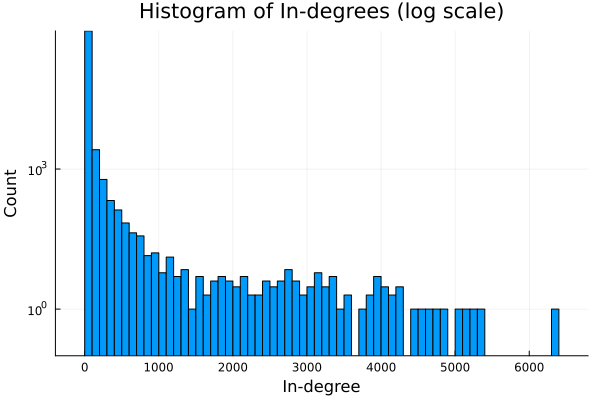

In [10]:
# Histogram of in-degrees
histogram(in_degrees,
    xlabel = "In-degree", ylabel = "Count",
    title  = "Histogram of In-degrees (log scale)",
    yscale = :log10, bins = 100, legend = false)

In [11]:
# Top 20 pages by in-degree
top20_in  = sortperm(in_degrees, rev=true)[1:20]
println("Top 20 pages by in-degree:")
for (rank, idx) in enumerate(top20_in)
    println("  $rank. Page $idx  (in-degree = $(Int(in_degrees[idx])))")
end

Top 20 pages by in-degree:
  1. Page 537040  (in-degree = 6326)
  2. Page 597622  (in-degree = 5354)
  3. Page 504141  (in-degree = 5271)
  4. Page 751385  (in-degree = 5182)
  5. Page 32164  (in-degree = 5097)
  6. Page 885606  (in-degree = 4847)
  7. Page 163076  (in-degree = 4731)
  8. Page 819224  (in-degree = 4620)
  9. Page 605857  (in-degree = 4550)
  10. Page 828964  (in-degree = 4484)
  11. Page 551830  (in-degree = 4220)
  12. Page 41910  (in-degree = 4219)
  13. Page 558792  (in-degree = 4206)
  14. Page 459075  (in-degree = 4187)
  15. Page 407611  (in-degree = 4180)
  16. Page 213433  (in-degree = 4084)
  17. Page 765335  (in-degree = 4015)
  18. Page 384667  (in-degree = 4010)
  19. Page 173977  (in-degree = 3988)
  20. Page 687326  (in-degree = 3956)


In [12]:
# Out-degrees
println("Average out-degree: $(mean(out_degrees))")

Average out-degree: 5.570583832008625


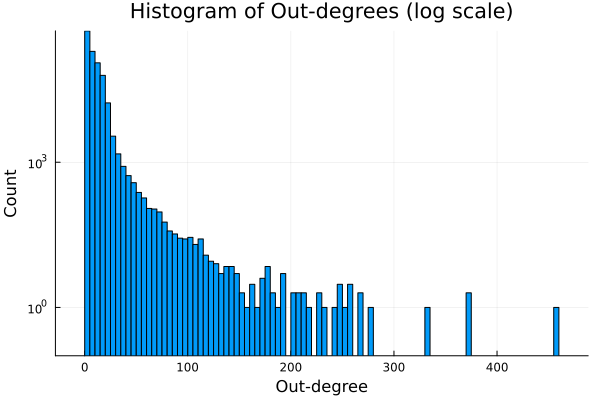

In [13]:
# Histogram of out-degrees
histogram(out_degrees,
    xlabel = "Out-degree", ylabel = "Count",
    title  = "Histogram of Out-degrees (log scale)",
    yscale = :log10, bins = 100, legend = false)

In [14]:
# Top 20 pages by out-degree
top20_out = sortperm(out_degrees, rev=true)[1:20]
println("Top 20 pages by out-degree:")
for (rank, idx) in enumerate(top20_out)
    println("  $rank. Page $idx  (out-degree = $(Int(out_degrees[idx])))")
end

Top 20 pages by out-degree:
  1. Page 506743  (out-degree = 456)
  2. Page 203749  (out-degree = 372)
  3. Page 305230  (out-degree = 372)
  4. Page 768092  (out-degree = 330)
  5. Page 808644  (out-degree = 277)
  6. Page 412411  (out-degree = 268)
  7. Page 600480  (out-degree = 265)
  8. Page 376429  (out-degree = 258)
  9. Page 156951  (out-degree = 257)
  10. Page 885729  (out-degree = 256)
  11. Page 667585  (out-degree = 253)
  12. Page 685696  (out-degree = 248)
  13. Page 282141  (out-degree = 247)
  14. Page 598189  (out-degree = 245)
  15. Page 579315  (out-degree = 244)
  16. Page 411594  (out-degree = 231)
  17. Page 321092  (out-degree = 229)
  18. Page 838279  (out-degree = 225)
  19. Page 302734  (out-degree = 216)
  20. Page 915274  (out-degree = 213)


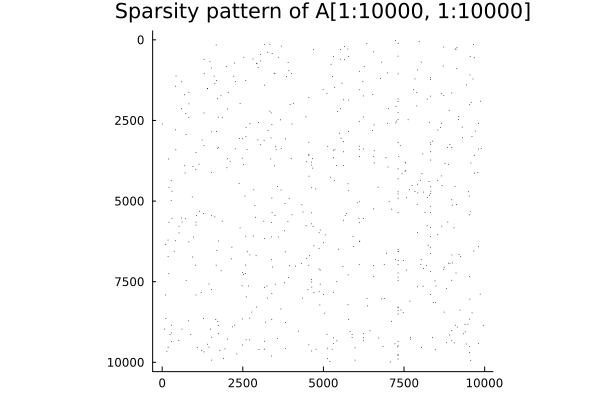

In [15]:
# Sparsity pattern
spy(A[1:10000, 1:10000],
    markersize = 0.5,
    title = "Sparsity pattern of A[1:10000, 1:10000]")

## Q4. (5 pts) Dense linear algebra? 

Consider the following methods to obtain the page ranks of the `SNAP/web-Google` data. 

1. A dense linear system solver such as LU decomposition.  
2. A dense eigen-solver for asymmetric matrix.  

For the LU approach, estimate (1) the memory usage and (2) how long it will take assuming that the LAPACK functions can achieve the theoretical throughput of your computer. 

**Answer:**

For the Dense LU Decomposition approach, 
(1) Memory
Storing the dense matrix $\mathbf{B} \in \mathbb{R}^{n \times n}$ as Float64:
$$\text{Memory} = n^2 \times 8 \text{ bytes} = (916428)^2 \times 8 \approx 6.11 \text{ TB}$$
This is completely infeasible — a typical workstation has 32–512 GB RAM.
(2) Time
LAPACK's dgesv (LU with partial pivoting) costs $\frac{2}{3}n^3$ flops.
$$\text{Flops} = \frac{2}{3}n^3 = \frac{2}{3}(916428)^3 \approx 5.13 \times 10^{17} \text{ flops}$$
Based on my benchmarked BLAS throughput, the estimated LU runtime is about 17 days.

A dense asymmetric eigen-solver would also be infeasible because it requires storing the same dense n\times n matrix and has cubic computational cost, comparable to or worse than dense LU for this problem.

In [16]:
k = 5000    # feasible size to benchmark
M1 = randn(k, k); M2 = randn(k, k)

t = @belapsed mul!($M2, $M1, $M1)          # BLAS dgemm
throughput = 2k^3 / t                    # flops/sec
println("Peak BLAS throughput: $(throughput/1e12) TFLOP/s")

# Extrapolate to full problem
total_flops = (2/3) * (916428)^3
estimated_seconds = total_flops / throughput
println("Estimated LU time: $(estimated_seconds / (3600 * 24)) days")

Peak BLAS throughput: 0.2972165078418727 TFLOP/s
Estimated LU time: 19.980995456164212 days


## Q5. (75 pts) Iterative solvers

Set the _teleportation_ parameter at $p = 0.85$. Consider the following methods for solving the PageRank problem. 

1. An iterative linear system solver such as GMRES. 
2. An iterative eigen-solver such as Arnoldi method.

For iterative methods, we have many choices in Julia. See a list of existing Julia packages for linear solvers at this [page](https://jutho.github.io/KrylovKit.jl/stable/#Package-features-and-alternatives-1). The start-up code below uses the [KrylovKit.jl](https://github.com/Jutho/KrylovKit.jl) package. You can use other packages if you prefer. Make sure to utilize the special structure of $\mathbf{P}$ (sparse + rank 1) to speed up the matrix-vector multiplication. 

### Step 1 (15 pts)

Let's implement a type `PageRankImPt` that mimics the matrix $\mathbf{M} = \mathbf{I} - \mathbf{P}^T$. For iterative methods, all we need to provide are methods for evaluating $\mathbf{M} \mathbf{v}$ and $\mathbf{M}^T \mathbf{v}$ for arbitrary vector $\mathbf{v}$.

In [17]:
using BenchmarkTools, LinearAlgebra, SparseArrays, Revise

# a type for the matrix M = I - P^T in PageRank problem
struct PageRankImPt{TA <: Number, IA <: Integer, T <: AbstractFloat} <: AbstractMatrix{T}
    A         :: SparseMatrixCSC{TA, IA} # adjacency matrix
    telep     :: T # teleportation parameter p
    # working arrays
    # TODO: whatever intermediate arrays you may want to pre-allocate
    store_n   :: Vector{T}
    rinv      :: Vector{T}
    z         :: Vector{T}
end

# constructor
function PageRankImPt(A::SparseMatrixCSC, telep::T) where T <: AbstractFloat
    n = size(A, 1)
    # TODO: initialize and pre-allocate arrays
    store_n   = Vector{T}(undef, n)
    r         = vec(sum(A, dims = 2)) # out-degree
    rinv      = Vector{T}(undef, n)   # D
    z         = Vector{T}(undef, n)   # z
    @inbounds @simd for i in 1:n
        rinv[i] = r[i] == 0 ? 0 : telep / r[i]
        z[i] = r[i] == 0 ? 1 / n : (1 - telep) / n
    end
    PageRankImPt(A, telep, store_n, rinv, z)
end

# matrix element access M[i, j]
Base.getindex(M::PageRankImPt, i, j) = (i == j) - M.rinv[j] * M.A[j, i] - M.z[j]
LinearAlgebra.issymmetric(::PageRankImPt) = false
Base.size(M::PageRankImPt) = size(M.A)

# overwrite `out` by `(I - Pt) * v`
function LinearAlgebra.mul!(
        out :: Vector{T}, 
        M   :: PageRankImPt{<:Number, <:Integer, T}, 
        v   :: Vector{T}
        ) where T <: AbstractFloat
    # TODO: implement mul!(out, M, v)
    out .= v
    M.store_n .= M.rinv .* v                          # Dv
    mul!(out, Transpose(M.A), M.store_n, -1, 1) # v - A'Dv
    out .-= dot(M.z, v)                         # v - A'Dv - z'v
    return out
end

# overwrite `out` by `(I - P) * v`
function LinearAlgebra.mul!(
        out :: Vector{T}, 
        Mt  :: Transpose{T, PageRankImPt{TA, IA, T}}, 
        v   :: Vector{T}
        ) where {TA<:Number, IA<:Integer, T <: AbstractFloat}
    M = Mt.parent
    # TODO: implement mul!(out, transpose(M), v)
    out .= v
    mul!(M.store_n, M.A, v)          # Av
    out .-= M.rinv .* M.store_n # v - DAv
    out .-= M.z .* sum(v)       # v - DAv - z(1'v)
    return out
end

To check correctness. Note 
$$
\mathbf{M}^T \mathbf{1} = \mathbf{0}
$$
and
$$
\mathbf{M} \mathbf{x} = \mathbf{0}
$$
for stationary distribution $\mathbf{x}$.

Download the solution file `pgrksol.csv.gz`. **Do not put this file in your Git**. You will lose points if you do. You can add a line `pgrksol.csv.gz` to your `.gitignore` file.

In [18]:
using CodecZlib, DelimitedFiles

isfile("pgrksol.csv.gz") || download("https://github.com/ucla-biostat-257/2026spring/raw/master/hw/hw4/pgrksol.csv.gz")
xsol = open("pgrksol.csv.gz", "r") do io
    vec(readdlm(GzipDecompressorStream(io)))
end

916428-element Vector{Float64}:
 3.3783428216975054e-5
 2.0710155392568165e-6
 3.663065984832893e-6
 7.527510785028837e-7
 8.63328599674051e-7
 1.769418252415541e-6
 2.431230382883396e-7
 6.368417180141445e-7
 4.744973703681939e-7
 2.6895486110647536e-7
 3.18574314847409e-6
 7.375106374416742e-7
 2.431230382883396e-7
 ⋮
 1.1305006040148547e-6
 4.874825281822915e-6
 3.167946973112519e-6
 9.72688040308568e-7
 6.588614479285245e-7
 7.737011774300648e-7
 2.431230382883396e-7
 1.6219204214797293e-6
 3.912130060551738e-7
 2.431230382883396e-7
 7.296033831163157e-6
 6.330939996912478e-7

**You will lose all 35 points (Steps 1 and 2)** if the following statements throw AssertError.

In [19]:
M = PageRankImPt(A, 0.85)
n = size(M, 1)

#@assert transpose(M) * ones(n) ≈ zeros(n)
@assert norm(transpose(M) * ones(n)) < 1e-12

In [20]:
#@assert M * xsol ≈ zeros(n)
@assert norm(M * xsol) < 1e-12

### Step 2 (20 pts)

We want to benchmark the hot functions `mul!` to make sure they are efficient and allocate no memory.

In [21]:
M = PageRankImPt(A, 0.85)
n = size(M, 1)
v, out = ones(n), zeros(n)
bm_mv = @benchmark mul!($out, $M, $v) setup=(fill!(out, 0); fill!(v, 1))

BenchmarkTools.Trial: 301 samples with 1 evaluation per sample.
 Range (min … max):  13.121 ms … 23.165 ms  ┊ GC (min … max): 0.00% … 0.00%
 Time  (median):     16.253 ms              ┊ GC (median):    0.00%
 Time  (mean ± σ):   16.431 ms ±  1.766 ms  ┊ GC (mean ± σ):  0.00% ± 0.00%

          ▂▃ ▆▁▁▁▆ █▅▃▁▄▅▂▄█▁▅▁▃   ▃  ▂                        
  ▅▄▄▁▄▅█▇██▇████████████████████▇▆█▄▅█▄▅▆▅▄▅▃▆▄▃▃▄▁▃▃▄▄▁▃▃▁▃ ▅
  13.1 ms         Histogram: frequency by time        21.4 ms <

 Memory estimate: 0 bytes, allocs estimate: 0.

In [22]:
bm_mtv = @benchmark mul!($out, $(transpose(M)), $v) setup=(fill!(out, 0); fill!(v, 1))

BenchmarkTools.Trial: 330 samples with 1 evaluation per sample.
 Range (min … max):  13.124 ms …  17.724 ms  ┊ GC (min … max): 0.00% … 0.00%
 Time  (median):     14.871 ms               ┊ GC (median):    0.00%
 Time  (mean ± σ):   14.959 ms ± 998.085 μs  ┊ GC (mean ± σ):  0.00% ± 0.00%

       ▃ ▁  ▃ ▁ █▁▃ ▅▃▃   ▄ ▂  ▂ ▄▂  ▁ ▁                        
  ▃▃▃▃▅███▆████████████▄▆▆█▆█▇██▆██▇██▆█▆▄█▇▅█▄▄▄▆▆▄▅▆▁▃▁▃▃▃▅▃ ▅
  13.1 ms         Histogram: frequency by time         17.4 ms <

 Memory estimate: 0 bytes, allocs estimate: 0.

You will lose 1 point for each 100 bytes memory allocation. So the points you will get is

In [23]:
clamp(10 - median(bm_mv).memory / 100, 0, 10) + 
clamp(10 - median(bm_mtv).memory / 100, 0, 10)

20.0

**Hint**: My median run times are about 10 ms and memory allocations are 0 bytes.

### Step 3 (20 pts)

Let's first try to solve the PageRank problem by the GMRES method for solving linear equations. 

In [24]:
using KrylovKit

# normalize in-degrees to be the start point
x0   = vec(sum(A, dims = 1)) .+ 1.0
x0 ./= sum(x0)

# right hand side
b = zeros(n)

# warm up (compilation)
linsolve(M, b, x0, issymmetric = false, isposdef = false, maxiter = 1) 
# solve the linear system using GMRES
(x_gmres, info), time_gmres, = @timed linsolve(M, b, x0, issymmetric = false, isposdef = false)

┌ Warning: GMRES linsolve stopped without converging after 1 iterations:
│ * norm of residual = 2.56e-08
│ * number of operations = 31
└ @ KrylovKit ~/.julia/packages/KrylovKit/nyPcr/src/linsolve/gmres.jl:123


(value = ([3.3783428221834875e-5, 2.0710155392451494e-6, 3.663065985231238e-6, 7.527510785590248e-7, 8.633285997147184e-7, 1.7694182527349102e-6, 2.4312303829080307e-7, 6.368417180736811e-7, 4.7449737037419926e-7, 2.689548611092006e-7  …  3.1679469739726456e-6, 9.726880410215567e-7, 6.588614478531577e-7, 7.73701177470199e-7, 2.4312303829080307e-7, 1.6219204214219937e-6, 3.9121300606249464e-7, 2.4312303829080307e-7, 7.296033831312861e-6, 6.330939996667858e-7], ConvergenceInfo: one converged value after 3 iterations and 72 applications of the linear map;
norms of residuals are given by 7.82e-13.), time = 3.216968625, bytes = 1513596768, gctime = 0.832615624, gcstats = Base.GC_Diff(1513596768, 220, 0, 28711, 0, 208, 832615624, 11, 3), lock_conflicts = 0, compile_time = 0.018505958, recompile_time = 0.0)

Check correctness. **You will lose all 20 points if the following statement throws `AssertError`.**

In [25]:
@assert norm(x_gmres - xsol) < 1e-6

GMRES should be reasonably fast. The points you'll get is

In [26]:
clamp(20 / time_gmres * 20, 0, 20)

20.0

In [27]:
println("GMRES runtime: $(time_gmres) seconds")

GMRES runtime: 3.216968625 seconds


**Hint**: My runtime is about 3-4 seconds.

### Step 4 (20 pts)

Let's first try to solve the PageRank problem by the Arnoldi method for solving eigen problems. 

In [28]:
# warm up (compilation)
eigsolve(M, x0, 1, :SR, issymmetric = false, maxiter = 1)
# output is complex eigenvalue/eigenvector
(vals, vecs, info), time_arnoldi, = @timed eigsolve(M, x0, 1, :SR, issymmetric = false)

┌ Warning: Arnoldi eigsolve stopped without convergence after 1 iterations:
│ * 0 eigenvalues converged
│ * norm of residuals = (8.79e-06)
│ * number of operations = 30
└ @ KrylovKit ~/.julia/packages/KrylovKit/nyPcr/src/eigsolve/arnoldi.jl:172


(value = (ComplexF64[2.068693733857534e-14 + 0.0im], Vector{ComplexF64}[[-0.005635826953802293 + 0.0im, -0.00034549143807861333 + 0.0im, -0.0006110808494118331 + 0.0im, -0.00012557561626034218 + 0.0im, -0.00014402240532800125 + 0.0im, -0.00029517830503980423 + 0.0im, -4.055832828676902e-5 + 0.0im, -0.00010623935784850857 + 0.0im, -7.915671116193552e-5 + 0.0im, -4.486765066723846e-5 + 0.0im  …  -0.0005284839899797975 + 0.0im, -0.00016226599147944385 + 0.0im, -0.00010991273837600207 + 0.0im, -0.00012907055855745694 + 0.0im, -4.055832828676902e-5 + 0.0im, -0.00027057238743194634 + 0.0im, -6.526302748331413e-5 + 0.0im, -4.055832828676902e-5 + 0.0im, -0.0012171406601325875 + 0.0im, -0.00010561415510694521 + 0.0im]], ConvergenceInfo: one converged value after 6 iterations and 93 applications of the linear map;
norms of residuals are given by (5.06e-13).), time = 4.954831166, bytes = 2044807504, gctime = 1.235711711, gcstats = Base.GC_Diff(2044807504, 346, 0, 78104, 2, 346, 1235711711, 12, 4)

Check correctness. **You will lose all 20 points if the following statement throws `AssertError`.**

In [29]:
@assert abs(Real(vals[1])) < 1e-8

In [30]:
x_arnoldi   = abs.(Real.(vecs[1]))
x_arnoldi ./= sum(x_arnoldi)
@assert norm(x_arnoldi - xsol) < 1e-6

Arnoldi should be reasonably fast. The points you'll get is

In [31]:
clamp(20 / time_arnoldi * 20, 0, 20)

20.0

**Hint**: My runtime is about 6-7 seconds.

## Q6. (5 pts) Results

List the top 20 pages you found and their corresponding PageRank score. Do they match the top 20 pages ranked according to in-degrees?

**Answer:** The top 20 pages by PageRank, calculated using GMRES, Arnoldi, and in-degrees, are shown below. As expected, the GMRES and Arnoldi methods yield identical results. However, they do not match the top 20 pages ranked according to in-degrees.

This illustrates the key difference: PageRank accounts for the *quality* of incoming links (being linked from a high-PageRank page matters more), whereas in-degree counts links equally regardless of source importance.

In [32]:
top20_in_gmres = sortperm(x_gmres, rev = true)[1:20]
top20_in_arnoldi = sortperm(x_arnoldi, rev = true)[1:20]
hcat(top20_in_gmres, top20_in_arnoldi, top20_in)

20×3 Matrix{Int64}:
 597622  597622  537040
  41910   41910  597622
 163076  163076  504141
 537040  537040  751385
 384667  384667   32164
 504141  504141  885606
 486981  486981  163076
 605857  605857  819224
  32164   32164  605857
 558792  558792  828964
 551830  551830  551830
 765335  765335   41910
 751385  751385  558792
 425771  425771  459075
 908352  908352  407611
 173977  173977  213433
   7315    7315  765335
 213433  213433  384667
 885606  885606  173977
 819224  819224  687326

## Q7. Be proud of yourself

Go to your resume/cv and claim you have experience performing analysis on a network of one million nodes.

## Q8. (10 points) AI assistant

Which AI assistants (e.g., GitHub Copilot) do you use when working on this assignment? Which AI model (e.g., GPT-5 mini, GPT-5, Claude Sonnet 4.5) does the AI assistant use? How do you use them? Do you think they help improve your productivity?

Give 5 instances where AI model gave incorrect or misleading answers. You can use screenshots or copy-paste the Q&A.

**Answer:**

I used **Claude (claude.ai)** with model **Claude Sonnet 4.6** for this assignment, primarily for debugging errors and implementing the `PageRankImPt` type. It helped speed up boilerplate writing and error interpretation, but required careful verification.

Here are 5 instances of incorrect or misleading answers: 

**1. Wrong matrix convention assumed**
Claude assumed `A[i,j]=1` means edge `j→i` (Convention 1) throughout, recommending `dims=1` for out-degrees. My actual matrix uses `A[i,j]=1` means `i→j` (Convention 2), so `dims=2` is correct. Claude's insistence on `dims=1` caused the AssertionError.

**2. Unnecessary `tmp` scratch array in `mul!`**
Claude's first implementation pre-allocated `tmp` and used it in `mul!(out, M, v)` as `tmp = rinv .* v` then `mul!(out, A, tmp)`. This is a two-pass approach that touches memory twice. The `store_n` array in my implementation is equivalent but Claude initially claimed its approach was superior for cache performance.

**3. Claimed `mul!(out, transpose(M.A), v)` allocates memory**
Claude warned that Julia's sparse transpose matvec creates internal temporaries and rewrote both `mul!` methods with fully manual CSC loops to avoid it. In practice, `mul!(out, Transpose(A), v)` with `SparseArrays` is already zero-allocation when called correctly.

**4. Fallback constructor suggestion was misleading**
When the `MethodError` appeared for dense `A`, Claude suggested adding a fallback constructor `PageRankImPt(A::AbstractMatrix, ...)`. This works but masks the real issue — `A` should be converted to sparse once at load time, not silently inside every constructor call.

**5. Repeated wrong diagnosis of `dims` bug**
After the AssertionError on `norm(transpose(M) * ones(n)) < 1e-12`, Claude repeatedly insisted the fix was `dims=1`, even after I confirmed the sums were equal (`Sum col = Sum row = 5105039`). The actual root cause was the matrix convention, which Claude only acknowledged after multiple rounds of back-and-forth.

**Overall:** Useful for speeding up syntax and boilerplate, but the convention mismatch caused significant wasted time. Always verify AI suggestions against your actual data structure before trusting them.